# Comparação completa: ABC × componentes 012 × 012 polinomial (grau 2)

**Objetivo:** selecionar automaticamente, via PyCaret, o melhor algoritmo para cada um dos seis parâmetros elétricos em **três representações fasoriais** e produzir tabelas com a evolução de MAPE e R², como a obtida para R1.

| Experimento | Preditores fornecidos | Engenharia de atributos | Alvos |
|---|---|---|---|
| `ABC` | 24 módulos e ângulos ABC | Nenhuma | R0, R1, L0, L1, C0, C1 |
| `SEQ_012` | 24 módulos e ângulos de sequência | Nenhuma | Mesmos seis |
| `SEQ_012_POLI2` | 24 módulos e ângulos de sequência | Polinômios de grau 2 pelo PyCaret | Mesmos seis |

- **18 seleções independentes:** 3 representações × 6 alvos; `compare_models(turbo=True)`, **sem `include` nem `exclude`**.
- **Mesma base MATLAB sem ruído**, com 29.419 cenários e divisão 80/20 (`random_state=42`), preservada em todas as condições.
- **Validação cruzada:** 5 dobras nos dados de treinamento; MAPE define o vencedor em cada seleção.
- **Avaliação:** MAPE, MAE, RMSE e R² no mesmo teste reservado; ranking integral da validação cruzada para cada seleção.
- **Sem otimização de hiperparâmetros nesta etapa**, sem ruído, sem médias fasoriais, sem novas simulações.

**Atenção ao custo computacional:** `polynomial_features=True` com 24 atributos gera até 324 atributos (sem o termo constante). O AutoML pode levar horas na máquina local. Cada ranking e resultado de teste é salvo assim que o respectivo experimento termina, reduzindo o risco de perder os resultados de uma execução interrompida.

## 0. Configurações

Coloque `Analise_PN_FP_5_Cenarios.csv` ao lado do notebook. Para instalar o ambiente, use Python 3.10/3.11 e PyCaret 3.3.2. A pasta de saída é nova e não sobrescreve os experimentos anteriores.

In [7]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ARQUIVO_BASE = Path('Analise_PN_FP_5_Cenarios.csv')
PASTA_SAIDA = Path('resultados_ABC_012_POLI2_AutoML')
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

SEMENTE_SPLIT = 42
FRACAO_TESTE = 0.20
DOBRAS_CV = 5
TURBO = True
N_JOBS = -1               # Ajuste de acordo com CPU e RAM; -1 utiliza CPUs disponíveis
SALVAR_MODELOS = True      # Preserva pipelines vencedores para a futura etapa de tuning
SALVAR_PREDICOES = False
AMOSTRAS_DISPERSAO = 3000
PLOTAR_DISPERSOES = True

ALVOS = ['R0', 'R1', 'L0', 'L1', 'C0', 'C1']
REPRESENTACOES = ('ABC', 'SEQ_012', 'SEQ_012_POLI2')
FASORES_ABC = [
    'VA_in', 'VB_in', 'VC_in', 'IA_in', 'IB_in', 'IC_in',
    'VA_out', 'VB_out', 'VC_out', 'IA_out', 'IB_out', 'IC_out'
]
CARACTERISTICAS_ABC = [f'{f}_{s}' for f in FASORES_ABC for s in ('mod', 'phase')]
METADADOS = ['Fator_Potencia', 'Tipo_FP']

# Os 18 experimentos ficam ativados por padrão.
# Para rodar apenas alguns durante um teste, altere estas duas variáveis.
REPRESENTACOES_EXECUTAR = list(REPRESENTACOES)
ALVOS_EXECUTAR = list(ALVOS)

assert set(REPRESENTACOES_EXECUTAR).issubset(REPRESENTACOES)
assert set(ALVOS_EXECUTAR).issubset(ALVOS)
print('Python:', sys.version.split()[0])
print('Execuções previstas:', len(REPRESENTACOES_EXECUTAR) * len(ALVOS_EXECUTAR))
print('Turbo:', TURBO, '| CV:', DOBRAS_CV, '| N_JOBS:', N_JOBS)

Python: 3.11.9
Execuções previstas: 18
Turbo: True | CV: 5 | N_JOBS: -1


## 1. Importação da base e particionamento 80/20 único

Os índices de treino e teste são calculados uma vez, a partir da base MATLAB original, e reutilizados nas três representações. O identificador de cenário e os metadados de fator de potência **não entram nas variáveis preditoras**.

In [8]:
if not ARQUIVO_BASE.exists():
    raise FileNotFoundError(
        f'Arquivo não encontrado: {ARQUIVO_BASE.resolve()}. '
        'Coloque o CSV MATLAB na mesma pasta do notebook.'
    )

orig = pd.read_csv(ARQUIVO_BASE).reset_index(drop=True)
exigidas = CARACTERISTICAS_ABC + ALVOS + METADADOS
faltantes = sorted(set(exigidas) - set(orig.columns))
assert not faltantes, f'Colunas ausentes no CSV: {faltantes}'
orig = orig[exigidas].copy()
colunas_numericas = CARACTERISTICAS_ABC + ALVOS + ['Fator_Potencia']
orig[colunas_numericas] = orig[colunas_numericas].apply(pd.to_numeric, errors='raise')
assert not orig[colunas_numericas].isna().any().any()
assert np.isfinite(orig[colunas_numericas].to_numpy(dtype=float)).all()
assert (orig[ALVOS].to_numpy() > 0).all()
assert (orig[[f'{f}_mod' for f in FASORES_ABC]].to_numpy() > 0).all()

orig['ID_Cenario'] = np.arange(len(orig), dtype=np.int64)
idx_treino, idx_teste = train_test_split(
    np.arange(len(orig)), test_size=FRACAO_TESTE,
    random_state=SEMENTE_SPLIT, shuffle=True
)
idx_treino = np.sort(idx_treino)
idx_teste = np.sort(idx_teste)
assert len(np.intersect1d(idx_treino, idx_teste)) == 0
assert len(idx_treino) + len(idx_teste) == len(orig)

pd.DataFrame({
    'ID_Cenario': orig['ID_Cenario'],
    'Particao': np.where(orig['ID_Cenario'].isin(idx_treino), 'Treino', 'Teste')
}).to_csv(PASTA_SAIDA / 'particao_80_20.csv', index=False)
np.savez_compressed(PASTA_SAIDA / 'particao_80_20.npz',
                    idx_treino=idx_treino, idx_teste=idx_teste)
print(f'Cenários: {len(orig):,} | Treino: {len(idx_treino):,} | Teste: {len(idx_teste):,}')

Cenários: 29,419 | Treino: 23,535 | Teste: 5,884


## 2. Construção das componentes simétricas de Fortescue

Reconstruímos os 12 fasores complexos utilizando **módulos e ângulos em graus** e calculamos as componentes 0, 1 e 2 nas duas extremidades. Em seguida, extraímos módulo e ângulo em graus de cada componente, formando 24 atributos em `SEQ_012`.

$$X_0=(X_A+X_B+X_C)/3,\qquad X_1=(X_A+aX_B+a^2X_C)/3,\qquad X_2=(X_A+a^2X_B+aX_C)/3,$$
com $a=e^{j2\pi/3}$.

A versão `SEQ_012_POLI2` usa **exatamente esses mesmos 24 atributos iniciais**; os termos polinomiais são gerados *dentro* do pipeline do PyCaret e ajustados somente nos dados de treinamento.

In [9]:
a = np.exp(2j * np.pi / 3)
abc_positivo = np.array([1+0j, a**2, a])

def fortescue_012(Xabc: np.ndarray) -> np.ndarray:
    assert Xabc.ndim == 2 and Xabc.shape[1] == 3
    matriz = np.array([[1,1,1], [1,a,a**2], [1,a**2,a]], dtype=np.complex128) / 3
    return Xabc @ matriz.T

def fortescue_inversa(X012: np.ndarray) -> np.ndarray:
    inv = np.array([[1,1,1], [1,a**2,a], [1,a,a**2]], dtype=np.complex128)
    return X012 @ inv.T

assert np.allclose(fortescue_012(abc_positivo[None, :]),
                   np.array([[0,1,0]]), atol=1e-12)

def abc_complexo(df: pd.DataFrame, tipo: str, extremo: str) -> np.ndarray:
    trio = []
    for fase in 'ABC':
        base = f'{tipo}{fase}_{extremo}'
        modulo = df[f'{base}_mod'].to_numpy(dtype=float)
        angulo = df[f'{base}_phase'].to_numpy(dtype=float)
        trio.append(modulo * np.exp(1j * np.deg2rad(angulo)))
    return np.stack(trio, axis=1)

colunas_seq = {}
componentes_complexas = {}
for extremo in ('in', 'out'):
    for tipo in ('V', 'I'):
        Xabc = abc_complexo(orig, tipo, extremo)
        X012 = fortescue_012(Xabc)
        assert np.allclose(fortescue_inversa(X012), Xabc, rtol=1e-10, atol=1e-8)
        componentes_complexas[(tipo, extremo)] = X012
        for s in range(3):
            nome = f'{tipo}{s}_{extremo}'
            colunas_seq[f'{nome}_mod'] = np.abs(X012[:, s])
            colunas_seq[f'{nome}_phase'] = np.rad2deg(np.angle(X012[:, s]))

base_012 = pd.DataFrame(colunas_seq)
CARACTERISTICAS_012 = list(base_012.columns)
assert len(CARACTERISTICAS_012) == len(CARACTERISTICAS_ABC) == 24
assert np.isfinite(base_012.to_numpy(dtype=float)).all()

base_012[ALVOS] = orig[ALVOS].copy()
base_012[METADADOS] = orig[METADADOS].copy()
base_012['ID_Cenario'] = orig['ID_Cenario'].copy()
base_abc = orig.copy()

assert base_abc['ID_Cenario'].equals(base_012['ID_Cenario'])
assert np.array_equal(base_abc[ALVOS].to_numpy(), base_012[ALVOS].to_numpy())

bases = {
    'ABC': base_abc,
    'SEQ_012': base_012,
    'SEQ_012_POLI2': base_012,  # transformação polinomial acontece no setup
}
atributos = {
    'ABC': CARACTERISTICAS_ABC,
    'SEQ_012': CARACTERISTICAS_012,
    'SEQ_012_POLI2': CARACTERISTICAS_012,
}
print('Fortescue e transformação inversa verificadas.')
print('24 atributos por representação. Alvos e partições idênticos.')

Fortescue e transformação inversa verificadas.
24 atributos por representação. Alvos e partições idênticos.


## 3. Baseline: média do alvo no treinamento

A comparação com um estimador constante ajuda a identificar quando um algoritmo praticamente reproduz o valor nominal do parâmetro.

In [10]:
from sklearn.dummy import DummyRegressor

baselines = []
for alvo in ALVOS:
    y_treino = orig.iloc[idx_treino][alvo].to_numpy(dtype=float)
    y_teste = orig.iloc[idx_teste][alvo].to_numpy(dtype=float)
    pred = np.full_like(y_teste, y_treino.mean())
    baselines.append({
        'Alvo': alvo,
        'MAPE_baseline_%': 100 * float(np.mean(np.abs((y_teste - pred) / y_teste))),
        'R2_baseline': float(r2_score(y_teste, pred)),
    })
baselines = pd.DataFrame(baselines)
baselines.to_csv(PASTA_SAIDA / 'baseline_media_treino.csv', index=False)
display(baselines.round(6))

,Alvo,MAPE_baseline_%,R2_baseline
0,R0,8.075872,-0.000008
1,R1,8.118623,-0.000184
2,L0,8.247535,-0.000028
3,L1,6.372799,-0.001479
4,C0,8.045219,-0.000090
5,C1,6.217300,-0.000473


## 4. AutoML: 18 seleções, rankings e métricas no teste

Para cada combinação de representação e parâmetro:

1. **`setup()`** recebe os mesmos cenários de treinamento e teste.
2. **`compare_models()`** considera os modelos disponíveis com `turbo=True`, sem limitar a lista de candidatos; seleciona pelo menor MAPE na validação cruzada de cinco dobras.
3. Salvamos o ranking completo e o pipeline vencedor, antes da futura busca de hiperparâmetros.
4. Calculamos MAPE, MAE, RMSE e R² no conjunto de teste reservado, com previsões na unidade física original.

**Apenas `SEQ_012_POLI2` utiliza `polynomial_features=True` e `polynomial_degree=2`.** Não há busca de hiperparâmetros (`tune_model`) nesta etapa.

Esta é a célula mais demorada. Os arquivos CSV são gravados após **cada** experimento, para preservar os resultados já concluídos em caso de interrupção.

In [11]:
try:
    import pycaret
    from pycaret.regression import RegressionExperiment
except ImportError as exc:
    raise ImportError('Instale pycaret==3.3.2 em Python 3.10 ou 3.11.') from exc

print('PyCaret:', pycaret.__version__)
assert pycaret.__version__.split('.')[0] == '3'


def metricas(y, p):
    y = np.asarray(y, dtype=np.float64)
    p = np.asarray(p, dtype=np.float64)
    assert np.isfinite(y).all() and np.isfinite(p).all()
    assert np.all(y != 0), 'MAPE requer alvos não nulos.'
    return {
        'MAPE_%': float(100 * np.mean(np.abs((y - p) / y))),
        'MAE': float(mean_absolute_error(y, p)),
        'RMSE': float(np.sqrt(mean_squared_error(y, p))),
        'R2': float(r2_score(y, p)),
    }

modelos = {}
experimentos = {}
rankings = []
campeoes_cv = []
resultados_teste = []
resultados_fp = []
amostras_dispersao = []

for representacao in REPRESENTACOES_EXECUTAR:
    dados = bases[representacao]
    colunas_X = atributos[representacao]
    usar_polinomios = (representacao == 'SEQ_012_POLI2')

    for alvo in ALVOS_EXECUTAR:
        print(f'\n===== {representacao} | {alvo} | polynomial={usar_polinomios} =====', flush=True)
        colunas = colunas_X + [alvo]
        treino = dados.iloc[idx_treino][colunas].reset_index(drop=True)
        teste = dados.iloc[idx_teste][colunas].reset_index(drop=True)
        assert len(colunas_X) == 24
        assert len(treino) == len(idx_treino) and len(teste) == len(idx_teste)

        exp = RegressionExperiment()
        exp.setup(
            data=treino,
            target=alvo,
            test_data=teste,
            session_id=SEMENTE_SPLIT,
            normalize=True,
            normalize_method='zscore',
            polynomial_features=usar_polinomios,
            polynomial_degree=2,
            fold_strategy='kfold',
            fold=DOBRAS_CV,
            fold_shuffle=True,
            index=False,
            html=False,
            verbose=False,
            n_jobs=N_JOBS,
        )

        melhor = exp.compare_models(
            sort='MAPE',
            fold=DOBRAS_CV,
            turbo=TURBO,
            errors='ignore',
            verbose=False,
        )
        tabela_cv = exp.pull().copy()
        if melhor is None or tabela_cv.empty:
            raise RuntimeError(f'Sem resultado do AutoML: {representacao}, {alvo}')

        # A tabela vem ordenada pelo menor MAPE (expressão fracionária no PyCaret).
        tabela_cv.index.name = 'ID_Algoritmo'
        tabela_cv.insert(0, 'Alvo', alvo)
        tabela_cv.insert(0, 'Representacao', representacao)
        tabela_cv.to_csv(
            PASTA_SAIDA / f'ranking_cv_{representacao}_{alvo}.csv', index=True
        )
        rankings.append(tabela_cv.reset_index())
        pd.concat(rankings, ignore_index=True).to_csv(
            PASTA_SAIDA / 'rankings_cv_todos.csv', index=False
        )

        primeira_linha = tabela_cv.iloc[0]
        campeoes_cv.append({
            'Representacao': representacao,
            'Alvo': alvo,
            'Algoritmo_selecionado': type(melhor).__name__,
            'Algoritmo_topo_ranking': str(primeira_linha.get('Model', '')),
            'MAPE_CV_%': float(primeira_linha['MAPE'] * 100),
            'R2_CV': float(primeira_linha['R2']),
            'Tempo_CV_seg': float(primeira_linha.get('TT (Sec)', np.nan)),
        })
        pd.DataFrame(campeoes_cv).to_csv(
            PASTA_SAIDA / 'campeoes_validacao_cruzada.csv', index=False
        )

        modelos[(representacao, alvo)] = melhor
        experimentos[(representacao, alvo)] = exp
        print('Selecionado:', type(melhor).__name__, flush=True)

        # Pipeline vencedor + transformações, para futura etapa de tuning.
        if SALVAR_MODELOS:
            exp.save_model(
                melhor,
                str(PASTA_SAIDA / f'modelo_{representacao}_{alvo}'),
                verbose=False,
            )

        X_teste = teste[colunas_X].copy()
        y = teste[alvo].to_numpy(dtype=np.float64)
        previsoes = exp.predict_model(
            melhor, data=X_teste, round=15, verbose=False
        )
        coluna_pred = ('prediction_label' if 'prediction_label' in previsoes.columns
                       else 'Label')
        if coluna_pred not in previsoes.columns:
            raise RuntimeError('Coluna de predição não localizada: ' + str(previsoes.columns))
        p = previsoes[coluna_pred].to_numpy(dtype=np.float64)
        assert len(y) == len(p) == len(idx_teste)

        linha_teste = {
            'Representacao': representacao,
            'Alvo': alvo,
            'Algoritmo': type(melhor).__name__,
            'N_teste': len(y),
            **metricas(y, p)
        }
        resultados_teste.append(linha_teste)
        pd.DataFrame(resultados_teste).to_csv(
            PASTA_SAIDA / 'metricas_teste_parciais.csv', index=False
        )
        print('Teste: MAPE={MAPE_%:.4f}% | R2={R2:.5f}'.format(**linha_teste), flush=True)

        detalhe = pd.DataFrame({
            'ID_Cenario': dados.iloc[idx_teste]['ID_Cenario'].to_numpy(),
            'Real': y,
            'Predito': p,
            'FP': dados.iloc[idx_teste]['Fator_Potencia'].to_numpy(),
            'Tipo_FP': dados.iloc[idx_teste]['Tipo_FP'].astype(str).to_numpy(),
        })
        detalhe['Condicao_FP'] = detalhe['FP'].map(lambda x: f'{x:.2f}') + '_' + detalhe['Tipo_FP']
        for condicao, sub in detalhe.groupby('Condicao_FP'):
            resultados_fp.append({
                'Representacao': representacao, 'Alvo': alvo,
                'Condicao_FP': condicao, 'N_teste': len(sub),
                **metricas(sub['Real'], sub['Predito']),
            })
        pd.DataFrame(resultados_fp).to_csv(
            PASTA_SAIDA / 'metricas_por_fator_potencia.csv', index=False
        )
        if SALVAR_PREDICOES:
            detalhe.to_csv(
                PASTA_SAIDA / f'predicoes_{representacao}_{alvo}.csv', index=False
            )
        amostra = detalhe.sample(min(AMOSTRAS_DISPERSAO, len(detalhe)),
                                 random_state=SEMENTE_SPLIT)
        amostra['Representacao'] = representacao
        amostra['Alvo'] = alvo
        amostras_dispersao.append(amostra)

print('\nSeleção e avaliação concluídas. Arquivos individuais já estão salvos.')

PyCaret: 3.3.2

===== ABC | R0 | polynomial=False =====
Selecionado: CatBoostRegressor
Teste: MAPE=7.9897% | R2=0.02132

===== ABC | R1 | polynomial=False =====
Selecionado: HuberRegressor
Teste: MAPE=7.5609% | R2=0.12343

===== ABC | L0 | polynomial=False =====
Selecionado: CatBoostRegressor
Teste: MAPE=7.8462% | R2=0.08875

===== ABC | L1 | polynomial=False =====
Selecionado: CatBoostRegressor
Teste: MAPE=0.5403% | R2=0.99149

===== ABC | C0 | polynomial=False =====
Selecionado: Lasso
Teste: MAPE=8.0452% | R2=-0.00009

===== ABC | C1 | polynomial=False =====
Selecionado: CatBoostRegressor
Teste: MAPE=0.3851% | R2=0.99558

===== SEQ_012 | R0 | polynomial=False =====
Selecionado: CatBoostRegressor
Teste: MAPE=3.3543% | R2=0.80793

===== SEQ_012 | R1 | polynomial=False =====
Selecionado: RandomForestRegressor
Teste: MAPE=5.9657% | R2=0.42399

===== SEQ_012 | L0 | polynomial=False =====
Selecionado: CatBoostRegressor
Teste: MAPE=1.6017% | R2=0.95015

===== SEQ_012 | L1 | polynomial=False

## 5. Tabela da dissertação: evolução dos três experimentos por parâmetro

A tabela principal compara **os algoritmos campeões em cada representação**, os respectivos MAPEs e R² **no mesmo conjunto de teste**. Abaixo dela, mostramos também os valores da validação cruzada que fundamentaram cada escolha.

**Interpretação metodológica:** os algoritmos e representações são selecionados na validação cruzada. A comparação no teste reservado descreve o resultado final, mas não deve ser usada para fazer sucessivos ajustes de configuração, para evitar sobreajuste ao próprio teste. A futura otimização de hiperparâmetros deverá utilizar apenas as dobras do treinamento.

In [12]:
resultado_teste = pd.DataFrame(resultados_teste)
campeoes_cv_df = pd.DataFrame(campeoes_cv)
assert not resultado_teste.empty

resultado_teste.to_csv(PASTA_SAIDA / 'metricas_teste_18_experimentos.csv', index=False)

rotulos = {
    'ABC': 'ABC original',
    'SEQ_012': 'Componentes 012',
    'SEQ_012_POLI2': '012 + polinomial grau 2',
}
ordem_experimentos = list(REPRESENTACOES)

# Tabela longa: 18 linhas se as três representações e seis parâmetros foram executados.
tabela_longa = resultado_teste.merge(
    campeoes_cv_df[['Representacao', 'Alvo', 'MAPE_CV_%', 'R2_CV']],
    on=['Representacao', 'Alvo'], how='left', validate='one_to_one'
)
tabela_longa['Experimento'] = tabela_longa['Representacao'].map(rotulos)
tabela_longa['Experimento'] = pd.Categorical(
    tabela_longa['Experimento'],
    categories=[rotulos[r] for r in ordem_experimentos], ordered=True
)
tabela_longa['Alvo'] = pd.Categorical(
    tabela_longa['Alvo'], categories=ALVOS, ordered=True
)
tabela_longa = tabela_longa.sort_values(['Alvo', 'Experimento']).reset_index(drop=True)

colunas_exibicao = [
    'Alvo', 'Experimento', 'Algoritmo', 'MAPE_%', 'R2',
    'MAE', 'RMSE', 'MAPE_CV_%', 'R2_CV', 'N_teste'
]
tabela_longa[colunas_exibicao].to_csv(
    PASTA_SAIDA / 'evolucao_por_parametro_18_linhas.csv', index=False
)
print('Evolução dos seis parâmetros (vencedores selecionados por CV):')
display(tabela_longa[colunas_exibicao].round(6))

# Exibe uma tabela de três linhas para cada alvo, como a de R1.
for alvo in ALVOS:
    sub = tabela_longa.loc[tabela_longa['Alvo'] == alvo, [
        'Experimento', 'Algoritmo', 'MAPE_%', 'R2', 'MAPE_CV_%', 'R2_CV'
    ]].copy()
    if not sub.empty:
        print(f'\n========== EVOLUÇÃO DE {alvo} ==========')
        display(sub.round(5))
        sub.to_csv(PASTA_SAIDA / f'evolucao_{alvo}.csv', index=False)

# Tabela horizontal, adequada para comparar os seis alvos em uma única página.
campos = ['Algoritmo', 'MAPE_%', 'R2']
comparacao = resultado_teste.pivot(
    index='Alvo', columns='Representacao', values=campos
)
comparacao.columns = [f'{campo}_{rep}' for campo, rep in comparacao.columns]
comparacao = comparacao.reindex(ALVOS).reset_index().merge(
    baselines, on='Alvo', how='left'
)
comparacao.to_csv(PASTA_SAIDA / 'comparacao_resumo_seis_parametros.csv', index=False)
print('\nTabela consolidada (6 parâmetros):')
display(comparacao.round(5))

# Campeão recomendado para FUTURA otimização: menor MAPE médio na validação cruzada.
# Não utilizamos o conjunto de teste para selecionar o modelo para tuning.
finalistas = campeoes_cv_df.sort_values(['Alvo', 'MAPE_CV_%'], ascending=True)
finalistas = finalistas.groupby('Alvo', as_index=False).first()
finalistas = finalistas.merge(
    resultado_teste[['Alvo', 'Representacao', 'MAPE_%', 'R2']],
    on=['Alvo', 'Representacao'], how='left', validate='one_to_one'
)
finalistas = finalistas.rename(columns={
    'Algoritmo_selecionado': 'Algoritmo_para_tuning',
    'Representacao': 'Representacao_para_tuning',
    'MAPE_%': 'MAPE_teste_%',
    'R2': 'R2_teste',
})
finalistas = finalistas.set_index('Alvo').reindex(ALVOS).reset_index()
finalistas.to_csv(PASTA_SAIDA / 'finalistas_para_tuning_por_CV.csv', index=False)
print('\nFinalistas para a futura etapa de hiperparâmetros (seleção por CV):')
display(finalistas.round(5))

esperado = len(REPRESENTACOES_EXECUTAR) * len(ALVOS_EXECUTAR)
assert len(resultado_teste) == esperado, (len(resultado_teste), esperado)
print(f'\nExperimentos avaliados: {len(resultado_teste)} / 18 previstos no estudo completo.')

Evolução dos seis parâmetros (vencedores selecionados por CV):


,Alvo,Experimento,Algoritmo,MAPE_%,R2,MAE,RMSE,MAPE_CV_%,R2_CV,N_teste
0,R0,ABC original,CatBoostRegressor,7.989727,0.021322,0.118589,0.149223,8.13,0.0097,5884
1,R0,Componentes 012,CatBoostRegressor,3.354339,0.807931,0.050041,0.066107,3.63,0.7863,5884
2,R0,012 + polinomial grau 2,BayesianRidge,1.293642,0.958125,0.019267,0.030867,1.34,0.9476,5884
3,R1,ABC original,HuberRegressor,7.560870,0.123428,0.003708,0.004663,7.71,0.1088,5884
4,R1,Componentes 012,RandomForestRegressor,5.965687,0.423992,0.002922,0.003780,6.35,0.3756,5884
5,R1,012 + polinomial grau 2,LinearRegression,0.900623,0.447359,0.000448,0.003702,2.30,-91.1062,5884
6,L0,ABC original,CatBoostRegressor,7.846186,0.088754,0.000439,0.000553,7.85,0.0812,5884
7,L0,Componentes 012,CatBoostRegressor,1.601723,0.950150,0.000090,0.000129,1.80,0.9382,5884
8,L0,012 + polinomial grau 2,CatBoostRegressor,1.183158,0.971264,0.000067,0.000098,1.27,0.9661,5884
9,L1,ABC original,CatBoostRegressor,0.540326,0.991486,0.000007,0.000010,0.57,0.9907,5884



========== EVOLUÇÃO DE R0 ==========


,Experimento,Algoritmo,MAPE_%,R2,MAPE_CV_%,R2_CV
0,ABC original,CatBoostRegressor,7.98973,0.02132,8.13,0.0097
1,Componentes 012,CatBoostRegressor,3.35434,0.80793,3.63,0.7863
2,012 + polinomial grau 2,BayesianRidge,1.29364,0.95813,1.34,0.9476



========== EVOLUÇÃO DE R1 ==========


,Experimento,Algoritmo,MAPE_%,R2,MAPE_CV_%,R2_CV
3,ABC original,HuberRegressor,7.56087,0.12343,7.71,0.1088
4,Componentes 012,RandomForestRegressor,5.96569,0.42399,6.35,0.3756
5,012 + polinomial grau 2,LinearRegression,0.90062,0.44736,2.30,-91.1062


... (9 outputs left out)

,Alvo,Algoritmo_ABC,Algoritmo_SEQ_012,Algoritmo_SEQ_012_POLI2,MAPE_%_ABC,MAPE_%_SEQ_012,MAPE_%_SEQ_012_POLI2,R2_ABC,R2_SEQ_012,R2_SEQ_012_POLI2,MAPE_baseline_%,R2_baseline
0,R0,CatBoostRegressor,CatBoostRegressor,BayesianRidge,7.989727,3.354339,1.293642,0.021322,0.807931,0.958125,8.07587,-0.00001
1,R1,HuberRegressor,RandomForestRegressor,LinearRegression,7.56087,5.965687,0.900623,0.123428,0.423992,0.447359,8.11862,-0.00018
2,L0,CatBoostRegressor,CatBoostRegressor,CatBoostRegressor,7.846186,1.601723,1.183158,0.088754,0.95015,0.971264,8.24754,-0.00003
3,L1,CatBoostRegressor,CatBoostRegressor,Ridge,0.540326,0.326955,0.322478,0.991486,0.996744,0.996853,6.37280,-0.00148
4,C0,Lasso,LinearRegression,BayesianRidge,8.045219,4.229704,1.249937,-0.00009,0.691802,0.959107,8.04522,-0.00009
5,C1,CatBoostRegressor,CatBoostRegressor,BayesianRidge,0.385125,0.313992,0.011399,0.995584,0.996589,0.999996,6.21730,-0.00047



Finalistas para a futura etapa de hiperparâmetros (seleção por CV):


,Alvo,Representacao_para_tuning,Algoritmo_para_tuning,Algoritmo_topo_ranking,MAPE_CV_%,R2_CV,Tempo_CV_seg,MAPE_teste_%,R2_teste
0,R0,SEQ_012_POLI2,BayesianRidge,Bayesian Ridge,1.34,0.9476,0.492,1.29364,0.95813
1,R1,SEQ_012_POLI2,LinearRegression,Linear Regression,2.30,-91.1062,0.180,0.90062,0.44736
2,L0,SEQ_012_POLI2,CatBoostRegressor,CatBoost Regressor,1.27,0.9661,29.800,1.18316,0.97126
3,L1,SEQ_012_POLI2,Ridge,Ridge Regression,0.33,0.9966,0.146,0.32248,0.99685
4,C0,SEQ_012_POLI2,BayesianRidge,Bayesian Ridge,1.31,0.9556,0.254,1.24994,0.95911
5,C1,SEQ_012_POLI2,BayesianRidge,Bayesian Ridge,0.01,1.0000,0.264,0.01140,1.00000



Experimentos avaliados: 18 / 18 previstos no estudo completo.


In [15]:
import pandas as pd

ranking = pd.read_csv(
    PASTA_SAIDA / 'ranking_cv_SEQ_012_POLI2_R1.csv'
)

ranking_completo = ranking.sort_values('MAPE').reset_index(drop=True)

ranking_completo.insert(
    0, 'Posicao', range(1, len(ranking_completo) + 1)
)

# Converter MAPE para porcentagem
ranking_completo['MAPE_%'] = ranking_completo['MAPE'] * 100

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 250
):
    display(ranking_completo)

,Posicao,ID_Algoritmo,Representacao,Alvo,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec),MAPE_%
0,1,lr,SEQ_012_POLI2,R1,Linear Regression,0.0011,0.0023,0.0367,-91.1062,0.0177,0.0230,0.180,2.30
1,2,ridge,SEQ_012_POLI2,R1,Ridge Regression,0.0011,0.0000,0.0016,0.9022,0.0015,0.0233,0.122,2.33
2,3,omp,SEQ_012_POLI2,R1,Orthogonal Matching Pursuit,0.0017,0.0000,0.0022,0.8084,0.0021,0.0339,0.120,3.39
3,4,catboost,SEQ_012_POLI2,R1,CatBoost Regressor,0.0026,0.0000,0.0034,0.5526,0.0032,0.0526,30.340,5.26
4,5,et,SEQ_012_POLI2,R1,Extra Trees Regressor,0.0029,0.0000,0.0037,0.4577,0.0035,0.0582,42.892,5.82
5,6,huber,SEQ_012_POLI2,R1,Huber Regressor,0.0029,0.0000,0.0037,0.4508,0.0036,0.0593,3.168,5.93
6,7,lightgbm,SEQ_012_POLI2,R1,Light Gradient Boosting Machine,0.0031,0.0000,0.0040,0.3770,0.0038,0.0631,2.182,6.31
7,8,rf,SEQ_012_POLI2,R1,Random Forest Regressor,0.0031,0.0000,0.0040,0.3760,0.0038,0.0636,216.098,6.36
8,9,gbr,SEQ_012_POLI2,R1,Gradient Boosting Regressor,0.0037,0.0000,0.0047,0.1239,0.0045,0.0764,69.732,7.64
9,10,ada,SEQ_012_POLI2,R1,AdaBoost Regressor,0.0040,0.0000,0.0050,0.0142,0.0048,0.0816,15.846,8.16


In [16]:
from sklearn.metrics import (
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score
)
import numpy as np

exp = experimentos[('SEQ_012_POLI2', 'R1')]

# Treinar Ridge com a configuração padrão
ridge = exp.create_model('ridge', verbose=False)

# Recuperar os mesmos dados de teste
dados = bases['SEQ_012_POLI2']
colunas = atributos['SEQ_012_POLI2'] + ['R1']

teste = dados.iloc[idx_teste][colunas].reset_index(drop=True)

# Predição com o pipeline polinomial
pred = exp.predict_model(ridge, data=teste, verbose=False)

y_real = teste['R1'].to_numpy()
y_pred = pred['prediction_label'].to_numpy()

print('MAPE (%):', mean_absolute_percentage_error(y_real, y_pred) * 100)
print('RMSE:', np.sqrt(mean_squared_error(y_real, y_pred)))
print('R²:', r2_score(y_real, y_pred))

MAPE (%): 2.19115589607178
RMSE: 0.0014728139286175768
R²: 0.9125395609252297


## 6. Gráficos de comparação e dispersão

As métricas são calculadas **sobre todas as 5.884 amostras de teste**, enquanto as dispersões exibem no máximo `AMOSTRAS_DISPERSAO` pontos por experimento, apenas para visualização.

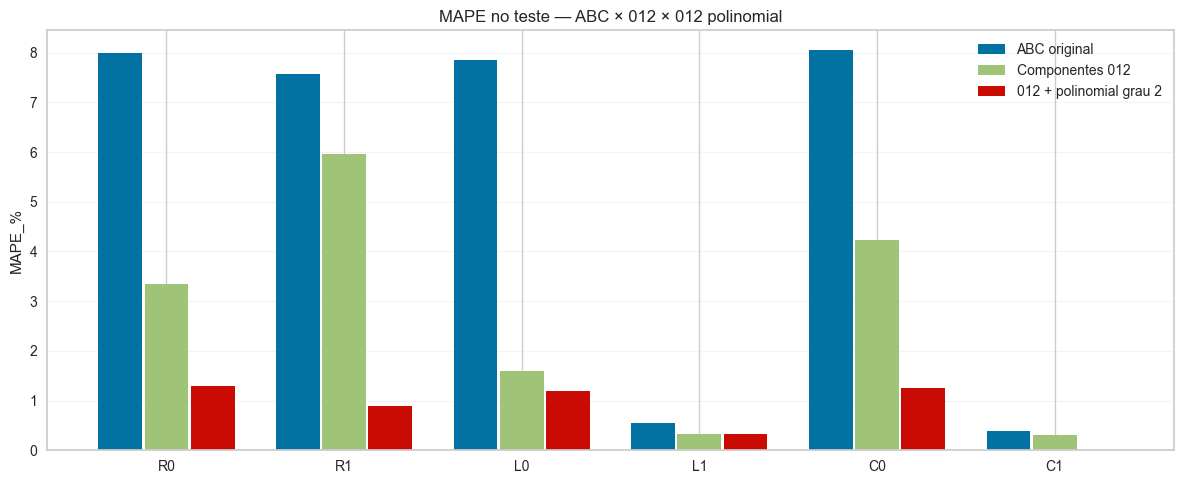

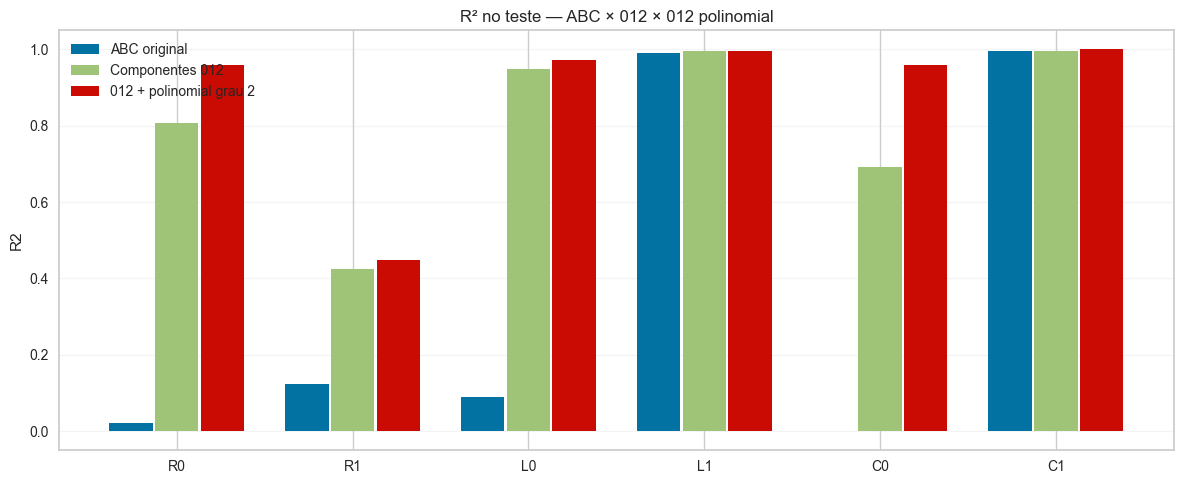

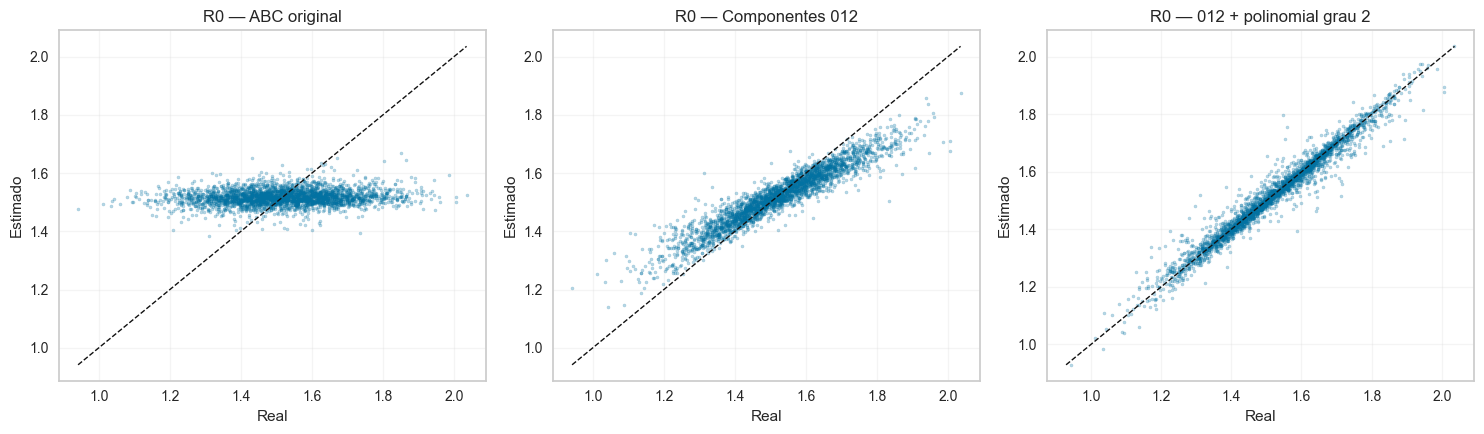

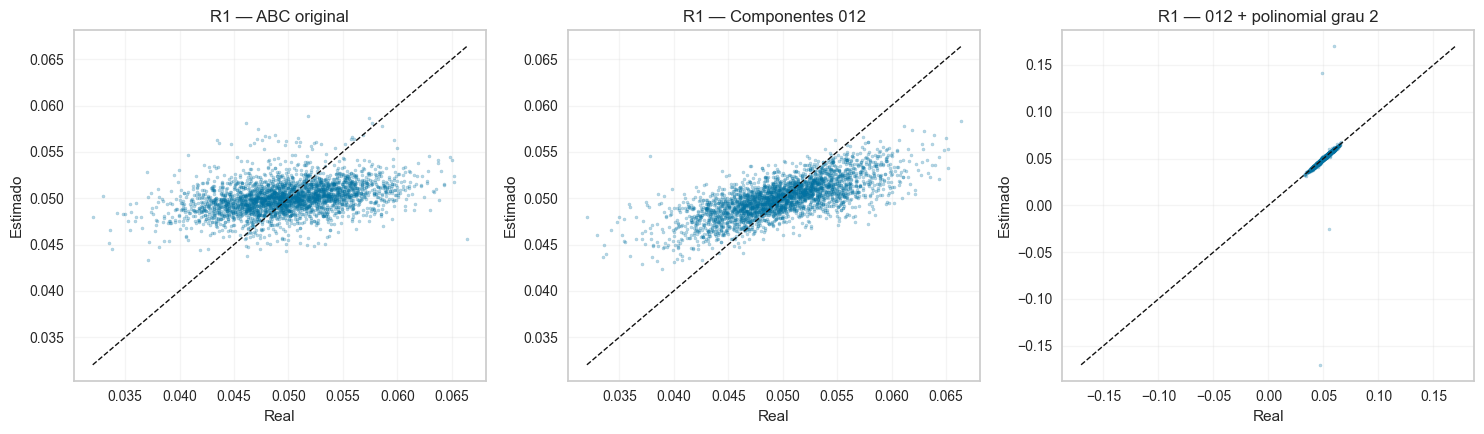

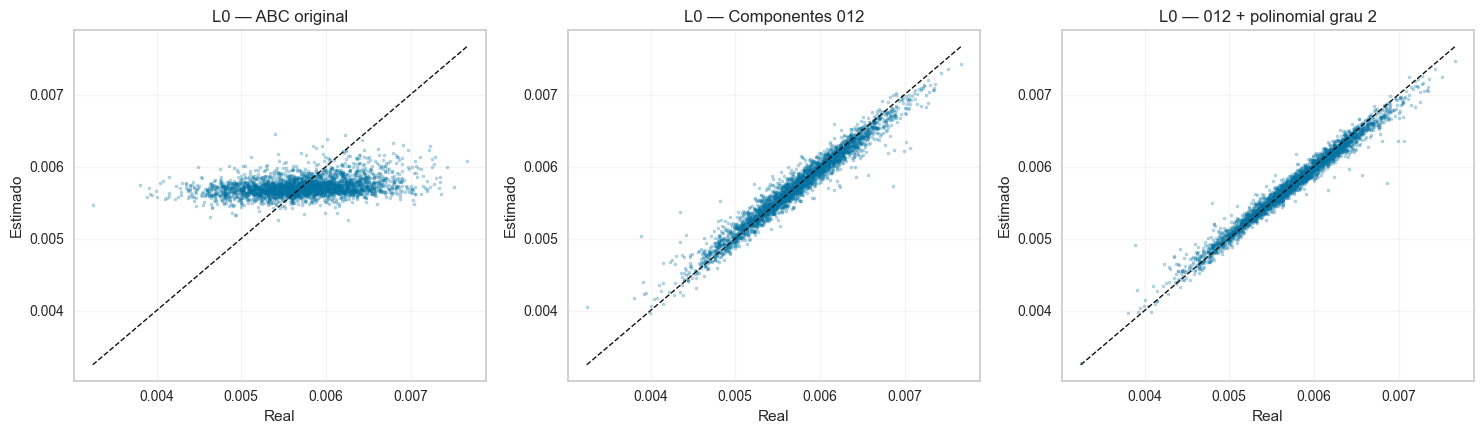

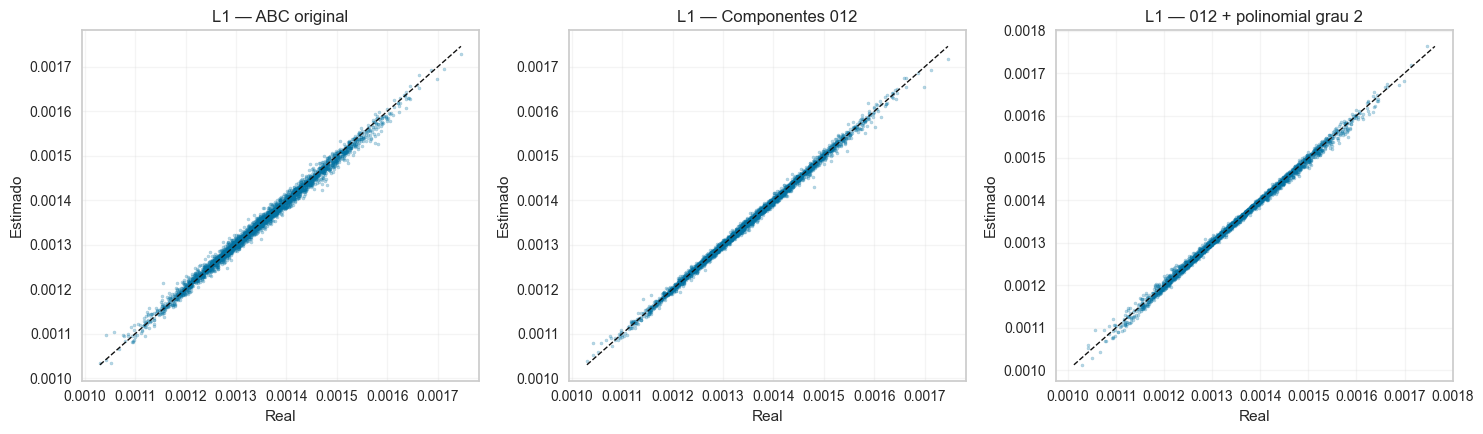

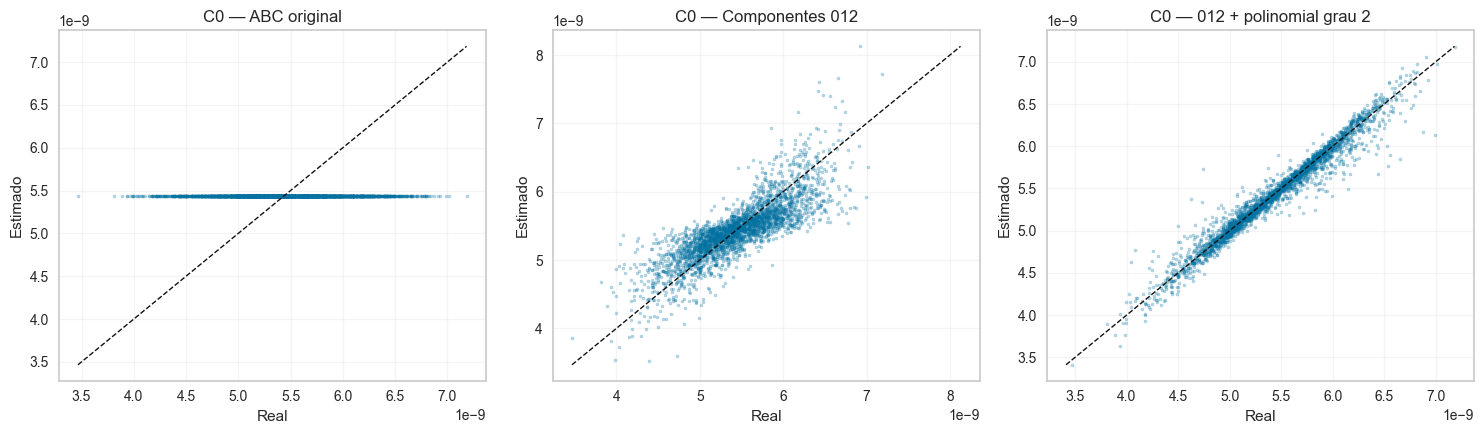

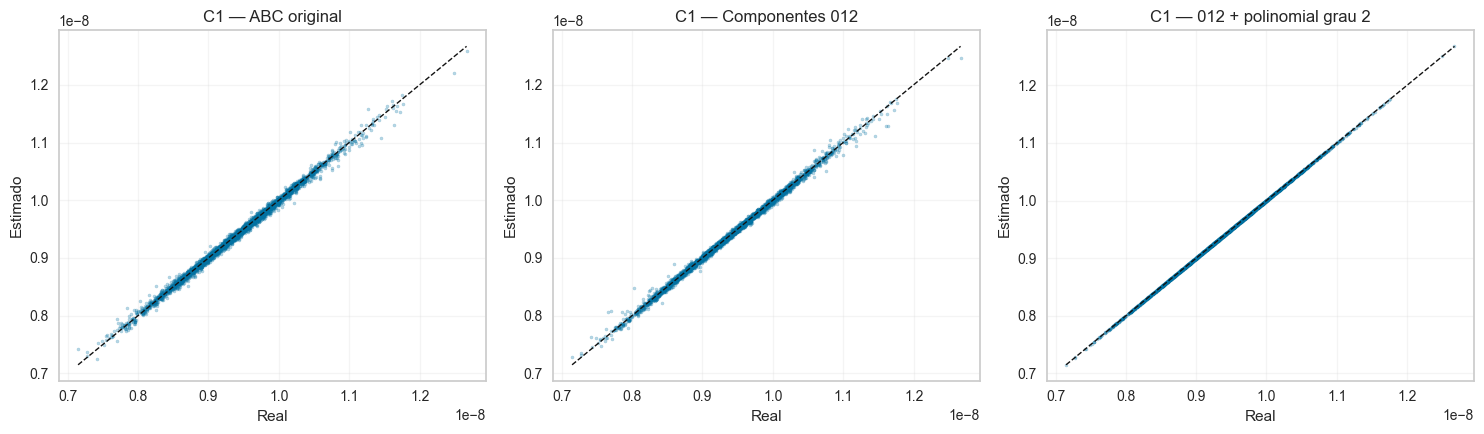

In [13]:
from matplotlib.ticker import MaxNLocator

for metrica, titulo, filename in [
    ('MAPE_%', 'MAPE no teste — ABC × 012 × 012 polinomial', 'comparacao_MAPE.png'),
    ('R2', 'R² no teste — ABC × 012 × 012 polinomial', 'comparacao_R2.png')
]:
    fig, ax = plt.subplots(figsize=(12, 5))
    x = np.arange(len(ALVOS))
    deslocamentos = np.linspace(-0.26, 0.26, len(REPRESENTACOES_EXECUTAR))
    largura = 0.74 / len(REPRESENTACOES_EXECUTAR)
    for j, representacao in enumerate(REPRESENTACOES_EXECUTAR):
        sub = resultado_teste.loc[resultado_teste['Representacao'] == representacao]
        serie = sub.set_index('Alvo')[metrica].reindex(ALVOS)
        ax.bar(x + deslocamentos[j], serie, width=largura,
               label=rotulos[representacao])
    ax.set_xticks(x, ALVOS)
    ax.set_ylabel(metrica)
    ax.set_title(titulo)
    ax.legend()
    ax.grid(axis='y', alpha=.2)
    fig.tight_layout()
    fig.savefig(PASTA_SAIDA / filename, dpi=160)
    plt.show()

if PLOTAR_DISPERSOES and amostras_dispersao:
    amostras = pd.concat(amostras_dispersao, ignore_index=True)
    for alvo in ALVOS:
        fig, axs = plt.subplots(1, len(REPRESENTACOES_EXECUTAR),
                                figsize=(5*len(REPRESENTACOES_EXECUTAR), 4.5),
                                squeeze=False)
        for ax, representacao in zip(axs[0], REPRESENTACOES_EXECUTAR):
            d = amostras.loc[
                (amostras['Alvo'] == alvo) &
                (amostras['Representacao'] == representacao)
            ]
            if d.empty:
                continue
            ax.scatter(d['Real'], d['Predito'], s=5, alpha=.28)
            mn = float(min(d['Real'].min(), d['Predito'].min()))
            mx = float(max(d['Real'].max(), d['Predito'].max()))
            ax.plot([mn,mx], [mn,mx], '--k', linewidth=1)
            ax.set_title(f'{alvo} — {rotulos[representacao]}')
            ax.set_xlabel('Real')
            ax.set_ylabel('Estimado')
            ax.grid(alpha=.2)
        fig.tight_layout()
        fig.savefig(PASTA_SAIDA / f'dispersao_{alvo}.png', dpi=150)
        plt.show()

## 7. Próximo passo — busca de hiperparâmetros (NÃO executada neste notebook)

Depois que tivermos a tabela de finalistas, a próxima etapa será aplicar `tune_model()` apenas aos **algoritmos e representações selecionados pela validação cruzada**, mantendo as mesmas partições e sem usar o teste para tomar decisões.

O CSV **`finalistas_para_tuning_por_CV.csv`** organiza a lista dos seis modelos escolhidos para essa etapa. Os pipelines vencedores ficam salvos na pasta de saída quando `SALVAR_MODELOS=True`.

**Ainda não introduzimos ruído neste estudo.** A comparação sem ruído deverá ser encerrada antes da extensão para N=1 e N=10.